<a href="https://colab.research.google.com/github/AyanGhosh218/Phishing-Project_2-/blob/main/Copy_of_Phishing_Website_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import libraries

In [8]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


Load dataset

In [9]:
import pandas as pd
df = pd.read_csv('/content/phishing.csv')
df.head()

,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,0,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
1,1,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
2,2,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
3,3,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,...,1,1,1,1,1,-1,1,-1,-1,1


Displays the last five records.

In [10]:
df.tail()

,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
11049,11049,1,-1,1,-1,1,1,1,1,-1,...,-1,-1,1,1,-1,-1,1,1,1,1
11050,11050,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,1,1,1,1,1,1,-1,1,-1
11051,11051,1,-1,1,1,1,-1,1,-1,-1,...,1,1,1,1,1,-1,1,0,1,-1
11052,11052,-1,-1,1,1,1,-1,-1,-1,1,...,-1,1,1,1,1,-1,1,1,1,-1
11053,11053,-1,-1,1,1,1,-1,-1,-1,1,...,1,1,-1,1,-1,-1,-1,1,-1,-1


Understand the dataset

In [11]:
print(df.shape)

(11054, 32)


Display Column names

In [12]:
print(df.columns)

Index(['Index', 'UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'Redirecting//',
       'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'Favicon',
       'NonStdPort', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL',
       'LinksInScriptTags', 'ServerFormHandler', 'InfoEmail', 'AbnormalURL',
       'WebsiteForwarding', 'StatusBarCust', 'DisableRightClick',
       'UsingPopupWindow', 'IframeRedirection', 'AgeofDomain', 'DNSRecording',
       'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'LinksPointingToPage',
       'StatsReport', 'class'],
      dtype='object')


Display Data types

In [13]:
print(df.dtypes)

Index                  int64
UsingIP                int64
LongURL                int64
ShortURL               int64
Symbol@                int64
Redirecting//          int64
PrefixSuffix-          int64
SubDomains             int64
HTTPS                  int64
DomainRegLen           int64
Favicon                int64
NonStdPort             int64
HTTPSDomainURL         int64
RequestURL             int64
AnchorURL              int64
LinksInScriptTags      int64
ServerFormHandler      int64
InfoEmail              int64
AbnormalURL            int64
WebsiteForwarding      int64
StatusBarCust          int64
DisableRightClick      int64
UsingPopupWindow       int64
IframeRedirection      int64
AgeofDomain            int64
DNSRecording           int64
WebsiteTraffic         int64
PageRank               int64
GoogleIndex            int64
LinksPointingToPage    int64
StatsReport            int64
class                  int64
dtype: object


Dataset Information

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11054 entries, 0 to 11053
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Index                11054 non-null  int64
 1   UsingIP              11054 non-null  int64
 2   LongURL              11054 non-null  int64
 3   ShortURL             11054 non-null  int64
 4   Symbol@              11054 non-null  int64
 5   Redirecting//        11054 non-null  int64
 6   PrefixSuffix-        11054 non-null  int64
 7   SubDomains           11054 non-null  int64
 8   HTTPS                11054 non-null  int64
 9   DomainRegLen         11054 non-null  int64
 10  Favicon              11054 non-null  int64
 11  NonStdPort           11054 non-null  int64
 12  HTTPSDomainURL       11054 non-null  int64
 13  RequestURL           11054 non-null  int64
 14  AnchorURL            11054 non-null  int64
 15  LinksInScriptTags    11054 non-null  int64
 16  ServerFormHandler    1

Statistical Description

In [15]:

df.describe()

,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
count,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,...,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000
mean,5526.500000,0.313914,-0.633345,0.738737,0.700561,0.741632,-0.734938,0.064049,0.251040,-0.336711,...,0.613353,0.816899,0.061335,0.377239,0.287407,-0.483626,0.721549,0.343948,0.719739,0.113986
std,3191.159272,0.949495,0.765973,0.674024,0.713625,0.670837,0.678165,0.817492,0.911856,0.941651,...,0.789845,0.576807,0.998162,0.926158,0.827680,0.875314,0.692395,0.569936,0.694276,0.993527
min,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,2763.250000,-1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,1.000000,1.000000,-1.000000,-1.000000,0.000000,-1.000000,1.000000,0.000000,1.000000,-1.000000
50%,5526.500000,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,0.000000,1.000000,-1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,0.000000,1.000000,1.000000
75%,8289.750000,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,11053.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


 Statistical summary

In [16]:
print(df.describe(include="all"))

              Index       UsingIP       LongURL      ShortURL       Symbol@  \
count  11054.000000  11054.000000  11054.000000  11054.000000  11054.000000   
mean    5526.500000      0.313914     -0.633345      0.738737      0.700561   
std     3191.159272      0.949495      0.765973      0.674024      0.713625   
min        0.000000     -1.000000     -1.000000     -1.000000     -1.000000   
25%     2763.250000     -1.000000     -1.000000      1.000000      1.000000   
50%     5526.500000      1.000000     -1.000000      1.000000      1.000000   
75%     8289.750000      1.000000     -1.000000      1.000000      1.000000   
max    11053.000000      1.000000      1.000000      1.000000      1.000000   

       Redirecting//  PrefixSuffix-    SubDomains         HTTPS  DomainRegLen  \
count   11054.000000   11054.000000  11054.000000  11054.000000  11054.000000   
mean        0.741632      -0.734938      0.064049      0.251040     -0.336711   
std         0.670837       0.678165      0.81

Remove unnecessary CSV index columns

In [17]:
df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed:")]


Identify target column

In [18]:
possible_targets = ["Result", "result", "class", "Class", "target", "Target"]

target_col = next(
    (col for col in possible_targets if col in df.columns),
    df.columns[-1]
)

print("Target Column:", target_col)




Target Column: class


Remove records with missing target

In [19]:
df = df.dropna(subset=[target_col]).copy()

Separate target values

In [20]:
print("\nOriginal Target Values:")
print(df[target_col].value_counts())


Original Target Values:
class
 1    6157
-1    4897
Name: count, dtype: int64


Convert target labels

In [21]:
def convert_target(value):

    value = str(value).strip().lower()

    # UCI dataset encoding
    if value in ["-1", "phishing", "phish"]:
        return 1

    if value in ["1", "legitimate", "legit", "safe"]:
        return 0

    if value in ["0"]:
        return 0

    raise ValueError(f"Unknown target label: {value}")


df[target_col] = df[target_col].apply(convert_target)

print("Target converted successfully!")

print("\n0 = Legitimate")
print("1 = Phishing")

print(df[target_col].value_counts())

Target converted successfully!

0 = Legitimate
1 = Phishing
class
0    6157
1    4897
Name: count, dtype: int64


Exploratory Data Analysis

Check missing values

In [22]:
print("Missing Values:")

print(df.isnull().sum())

print("\nTotal Missing Values:")

print(df.isnull().sum().sum())

Missing Values:
Index                  0
UsingIP                0
LongURL                0
ShortURL               0
Symbol@                0
Redirecting//          0
PrefixSuffix-          0
SubDomains             0
HTTPS                  0
DomainRegLen           0
Favicon                0
NonStdPort             0
HTTPSDomainURL         0
RequestURL             0
AnchorURL              0
LinksInScriptTags      0
ServerFormHandler      0
InfoEmail              0
AbnormalURL            0
WebsiteForwarding      0
StatusBarCust          0
DisableRightClick      0
UsingPopupWindow       0
IframeRedirection      0
AgeofDomain            0
DNSRecording           0
WebsiteTraffic         0
PageRank               0
GoogleIndex            0
LinksPointingToPage    0
StatsReport            0
class                  0
dtype: int64

Total Missing Values:
0


Check duplicate records

In [23]:
print("Duplicate Records:")

print(df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

print("\nShape After Removing Duplicates:")

print(df.shape)

Duplicate Records:
0

Shape After Removing Duplicates:
(11054, 32)


Check phishing and legitimate counts

In [24]:
class_counts = df[target_col].value_counts().sort_index()

print("Website Classification:")

print(class_counts)

print("\n0 = Legitimate")
print("1 = Phishing")

Website Classification:
class
0    6157
1    4897
Name: count, dtype: int64

0 = Legitimate
1 = Phishing


Visualize class distribution

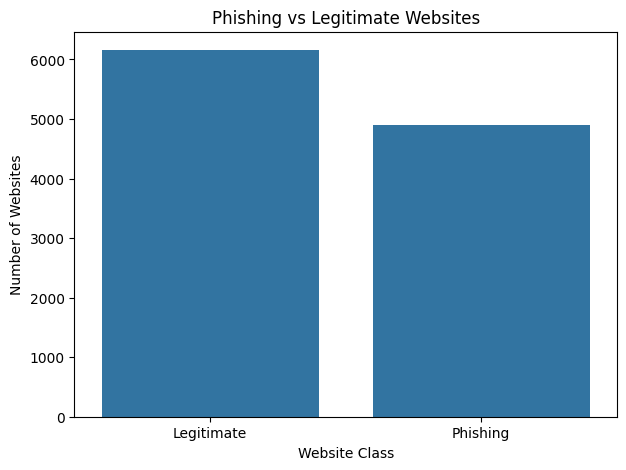

In [25]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x=target_col,
    data=df
)

plt.title("Phishing vs Legitimate Websites")

plt.xlabel("Website Class")

plt.ylabel("Number of Websites")

plt.xticks([0, 1], ["Legitimate", "Phishing"])

plt.show()

Feature correlation heatmap

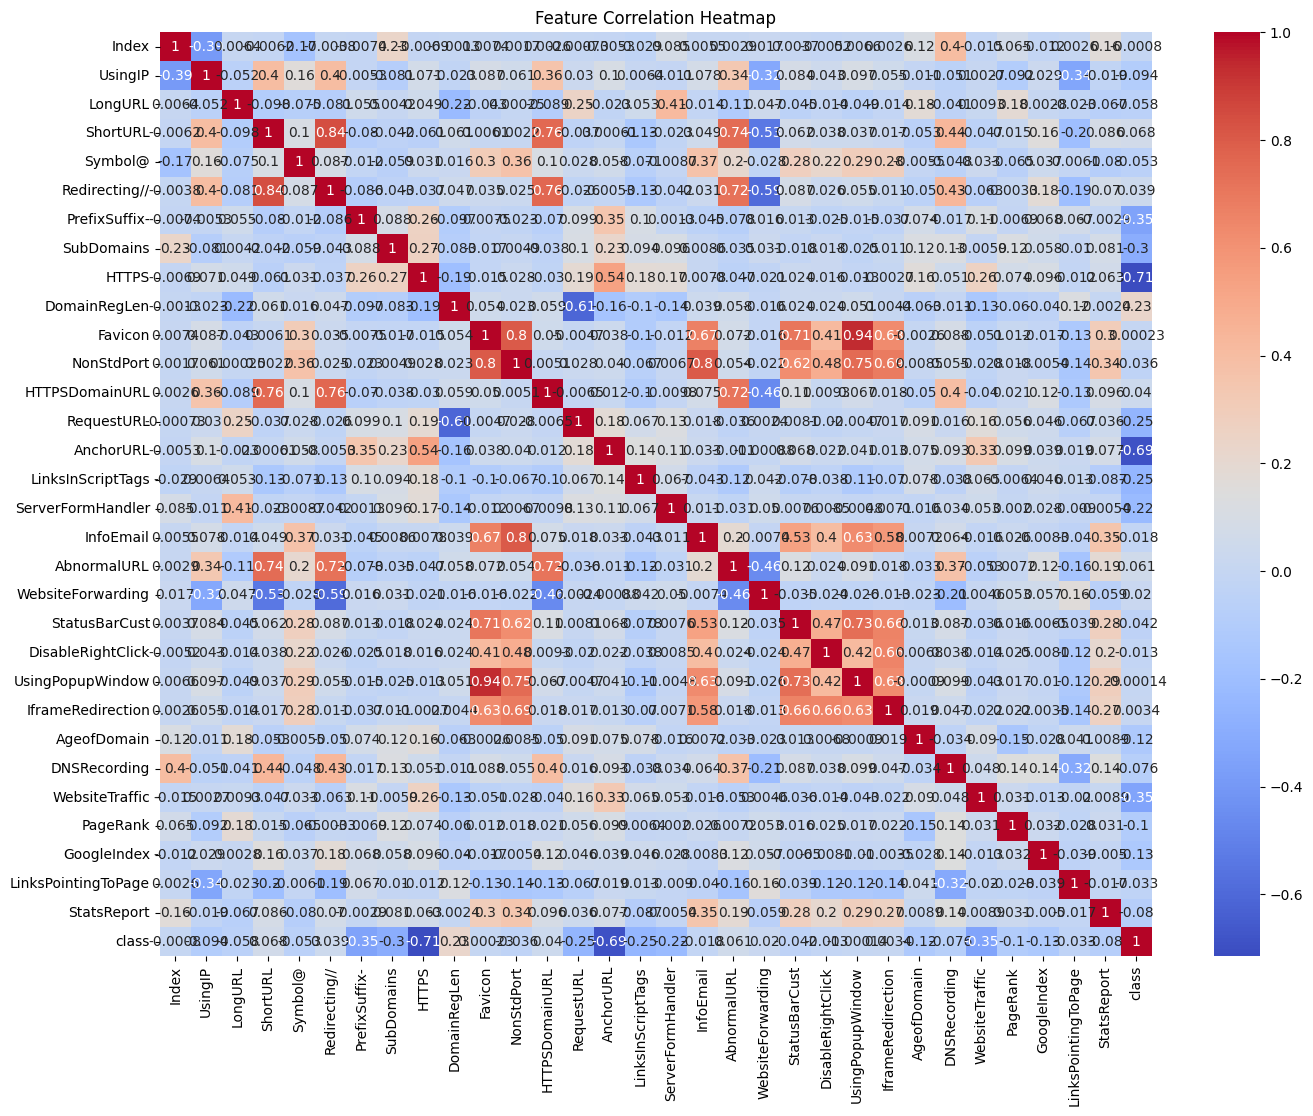

In [26]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(16, 12))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=True
)

plt.title("Feature Correlation Heatmap")

plt.show()

Data preprocessing

Separate X and y

In [27]:
X = df.drop(columns=[target_col])

y = df[target_col]

print("Input Features Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features Shape: (11054, 31)
Target Shape: (11054,)

Input Features:
   Index  UsingIP  LongURL  ShortURL  Symbol@  Redirecting//  PrefixSuffix-  \
0      0        1        1         1        1              1             -1   
1      1        1        0         1        1              1             -1   
2      2        1        0         1        1              1             -1   
3      3        1        0        -1        1              1             -1   
4      4       -1        0        -1        1             -1             -1   

   SubDomains  HTTPS  DomainRegLen  ...  DisableRightClick  UsingPopupWindow  \
0           0      1            -1  ...                  1                 1   
1          -1     -1            -1  ...                  1                 1   
2          -1     -1             1  ...                  1                 1   
3           1      1            -1  ...                  1                -1   
4           1      1            -1  ...            

Identify numerical and categorical columns

In [28]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:", len(numeric_features))

print("Categorical Features:", len(categorical_features))

Numerical Features: 31
Categorical Features: 0


Create preprocessing pipeline

In [29]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Split the dataset into training and testing

Train-test split

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")

print(y_train.value_counts())

print("\nTesting Target Distribution:")

print(y_test.value_counts())

Training Data: (8843, 31)
Testing Data: (2211, 31)

Training Target Distribution:
class
0    4925
1    3918
Name: count, dtype: int64

Testing Target Distribution:
class
0    1232
1     979
Name: count, dtype: int64


Train three machine learning models

Train Logistic Regression

In [31]:
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


Train Decision Tree

In [32]:
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

print("Decision Tree Training Completed!")

Decision Tree Training Completed!


Train Random Forest

In [33]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


Compare model performance

In [34]:
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

comparison_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")

display(
    comparison_df.round(4)
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9276,0.9333,0.9009,0.9168
1,Decision Tree,0.9516,0.9532,0.9367,0.9449
2,Random Forest,0.9711,0.9761,0.9581,0.9670


Visualize model comparison

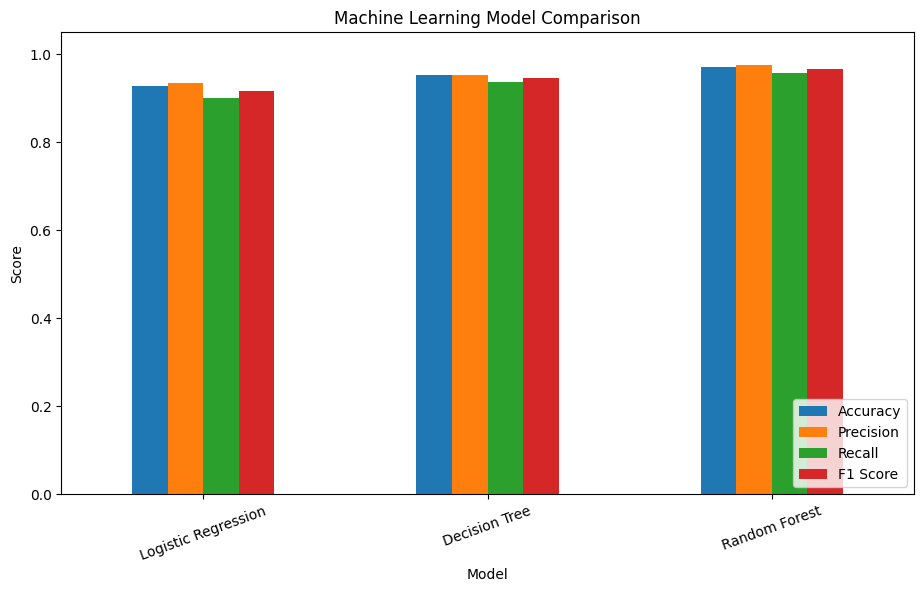

In [35]:
comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Machine Learning Model Comparison")

plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=20)

plt.legend(loc="lower right")

plt.show()

Confusion matrices

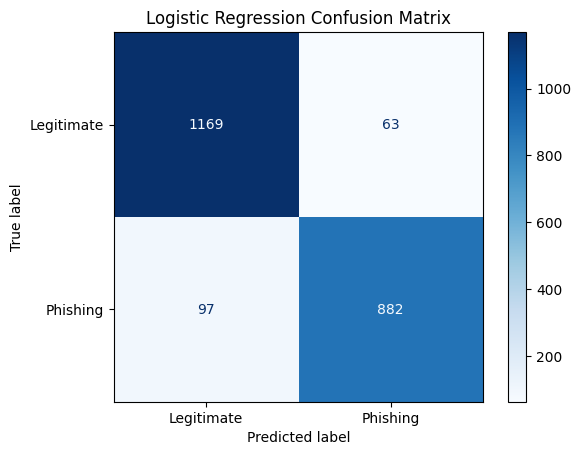

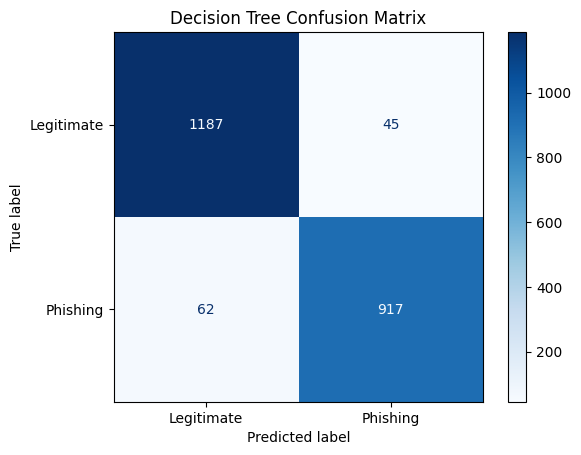

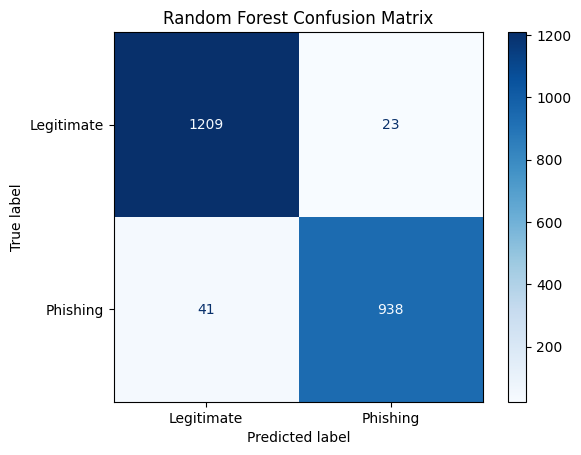

In [36]:
for name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Phishing"]
    )

    display_obj.plot(cmap="Blues")

    plt.title(name + " Confusion Matrix")

    plt.show()

Generate classification reports

In [37]:
for name, model in models.items():

    print("\n", "=" * 50)

    print(name)

    print("=" * 50)

    y_pred = model.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "Legitimate",
                "Phishing"
            ],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

  Legitimate       0.92      0.95      0.94      1232
    Phishing       0.93      0.90      0.92       979

    accuracy                           0.93      2211
   macro avg       0.93      0.92      0.93      2211
weighted avg       0.93      0.93      0.93      2211


Decision Tree
              precision    recall  f1-score   support

  Legitimate       0.95      0.96      0.96      1232
    Phishing       0.95      0.94      0.94       979

    accuracy                           0.95      2211
   macro avg       0.95      0.95      0.95      2211
weighted avg       0.95      0.95      0.95      2211


Random Forest
              precision    recall  f1-score   support

  Legitimate       0.97      0.98      0.97      1232
    Phishing       0.98      0.96      0.97       979

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97

Cross-validation

In [38]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="recall",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Average Recall": scores.mean()
    })

cv_df = pd.DataFrame(cv_results)

print("5-FOLD CROSS-VALIDATION RESULTS")

display(cv_df.round(4))

5-FOLD CROSS-VALIDATION RESULTS


,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Average Recall
0,Logistic Regression,0.9094,0.9222,0.9043,0.8902,0.8978,0.9048
1,Decision Tree,0.9452,0.9388,0.9413,0.9246,0.9285,0.9357
2,Random Forest,0.9554,0.9592,0.9579,0.9566,0.9438,0.9546


Hyperparameter tuning

Logistic Regression tuning

In [39]:
lr_params = {
    "classifier__C": [0.1, 1, 10],
    "classifier__solver": ["liblinear", "lbfgs"]
}

lr_grid = GridSearchCV(
    estimator=lr_model,
    param_grid=lr_params,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")

print(lr_grid.best_params_)

print("Best Cross-validation Recall:")

print(lr_grid.best_score_)

Best Logistic Regression Parameters:
{'classifier__C': 0.1, 'classifier__solver': 'liblinear'}
Best Cross-validation Recall:
0.9053033857221049


Decision Tree tuning

In [40]:
dt_params = {
    "classifier__max_depth": [None, 5, 10, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__criterion": ["gini", "entropy"]
}

dt_grid = GridSearchCV(
    estimator=dt_model,
    param_grid=dt_params,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree Parameters:")

print(dt_grid.best_params_)

print("Best Cross-validation Recall:")

print(dt_grid.best_score_)

Best Decision Tree Parameters:
{'classifier__criterion': 'entropy', 'classifier__max_depth': 10, 'classifier__min_samples_split': 10}
Best Cross-validation Recall:
0.9412972085385878


Random Forest tuning

In [41]:
rf_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_params,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")

print(rf_grid.best_params_)

print("Best Cross-validation Recall:")

print(rf_grid.best_score_)

Best Random Forest Parameters:
{'classifier__max_depth': 20, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Best Cross-validation Recall:
0.95686332004066


Best model selection

In [42]:
tuned_models = {
    "Logistic Regression": lr_grid,
    "Decision Tree": dt_grid,
    "Random Forest": rf_grid
}

tuned_results = []

for name, grid in tuned_models.items():

    tuned_results.append({
        "Model": name,
        "Best CV Recall": grid.best_score_,
        "Best Parameters": str(grid.best_params_)
    })

tuned_comparison = pd.DataFrame(tuned_results)

print("TUNED MODEL COMPARISON")

display(tuned_comparison)

# Select model with highest CV recall
best_name = max(
    tuned_models,
    key=lambda name: tuned_models[name].best_score_
)

best_model = tuned_models[best_name].best_estimator_

print("\nSelected Best Model:", best_name)

TUNED MODEL COMPARISON


,Model,Best CV Recall,Best Parameters
0,Logistic Regression,0.905303,"{'classifier__C': 0.1, 'classifier__solver': '..."
1,Decision Tree,0.941297,"{'classifier__criterion': 'entropy', 'classifi..."
2,Random Forest,0.956863,"{'classifier__max_depth': 20, 'classifier__min..."



Selected Best Model: Random Forest


Evaluate selected model

In [43]:
final_predictions = best_model.predict(X_test)

print("FINAL SELECTED MODEL:", best_name)

print("\nAccuracy:",
      accuracy_score(y_test, final_predictions))

print("\nPrecision:",
      precision_score(y_test, final_predictions))

print("\nRecall:",
      recall_score(y_test, final_predictions))

print("\nF1 Score:",
      f1_score(y_test, final_predictions))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["Legitimate", "Phishing"]
    )
)

FINAL SELECTED MODEL: Random Forest

Accuracy: 0.9687924016282226

Precision: 0.972972972972973

Recall: 0.9560776302349336

F1 Score: 0.964451313755796

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.97      0.98      0.97      1232
    Phishing       0.97      0.96      0.96       979

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211



Final confusion matrix

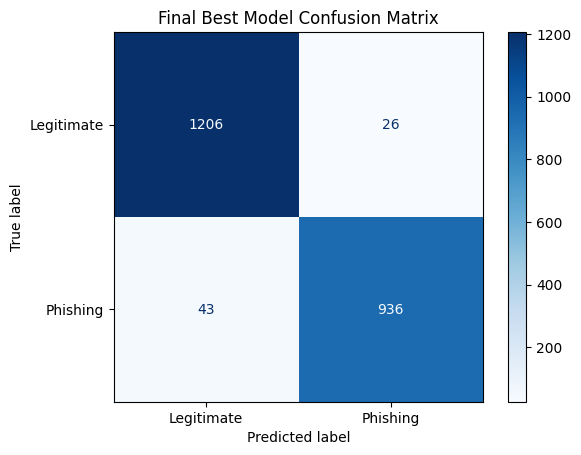

In [44]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["Legitimate", "Phishing"],
    cmap="Blues"
)

plt.title("Final Best Model Confusion Matrix")

plt.show()

Save model

In [45]:
model_data = {
    "model": best_model,
    "feature_columns": X.columns.tolist(),
    "best_model_name": best_name
}

joblib.dump(
    model_data,
    "phishing_detection_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


Download saved model

In [46]:
from google.colab import files

files.download("phishing_detection_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Add new website data

In [47]:
import pandas as pd

# Create dummy features matching 31 expected columns (including index as the first column)
new_data = pd.DataFrame([
    [1, -1, 1, 1, 0, 1] + [0] * 25,
    [2, 1, -1, 0, 1, -1] + [1] * 25
])

new_data.to_csv("new_website_data.csv", index=False)

print("New website data saved with 31 columns!")

New website data saved with 31 columns!


Load your saved model and predict

In [48]:
import joblib
import pandas as pd

# Load saved Random Forest model dictionary
model_data = joblib.load("phishing_detection_model.pkl")
model = model_data["model"]
feature_columns = model_data["feature_columns"]

print("Model loaded successfully!")

# Load new website data
new_data = pd.read_csv("new_website_data.csv")

# Map the column names expected by the model
if len(new_data.columns) == len(feature_columns):
    new_data.columns = feature_columns
else:
    print(f"Warning: new_data has {len(new_data.columns)} columns, but the model expects {len(feature_columns)} columns.")

# Predict
predictions = model.predict(new_data)

# Display results
for i, prediction in enumerate(predictions):

    if prediction == 1:
        result = "Phishing Website"

    elif prediction == 0:
        result = "Legitimate Website"

    else:
        result = f"Unknown label: {prediction}"

    print(f"Website {i+1}: {result}")

# Save prediction results
new_data["Prediction"] = predictions

new_data.to_csv("prediction_results.csv", index=False)

print("Prediction completed!")
print("Results saved in prediction_results.csv")

Model loaded successfully!
Website 1: Legitimate Website
Website 2: Legitimate Website
Prediction completed!
Results saved in prediction_results.csv
